In [100]:
import torch
from torch import nn
from torchvision import datasets, transforms

from pathlib import Path
from PIL import Image

import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader

import torchmetrics
from torchsummary import summary
from torchcodec.decoders import decode_image
from tqdm.auto import tqdm

In [2]:
BASE_DIR = "C:/Python-ML/data/seg_data"
TRAIN_DIR = "/seg_train"
TEST_DIR = "/seg_test"

In [3]:
# Get the path of the data
class CustomImageDataset(Dataset):
    def __init__(self, root_dir: str | Path, transform=None):
        self.root_dir = Path(root_dir)
        # Recursively find all .jpg files
        self.image_paths = sorted(self.root_dir.rglob("*/*.jpg"))
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        # Extract parent folder name as label
        label_name = img_path.parent.name 
        
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
            
        return image, label_name

In [4]:
train_data_dir = BASE_DIR + TRAIN_DIR
test_data_dir =  BASE_DIR + TEST_DIR

In [240]:
train_transform = transforms.Compose([
    transforms.Resize(size = (64, 64)),
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

In [241]:
train_data = datasets.ImageFolder(train_data_dir, train_transform)
test_data = datasets.ImageFolder(test_data_dir, test_transform)
train_data, test_data

(Dataset ImageFolder
     Number of datapoints: 14034
     Root location: C:/Python-ML/data/seg_data/seg_train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                Grayscale(num_output_channels=1)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 3000
     Root location: C:/Python-ML/data/seg_data/seg_test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                Grayscale(num_output_channels=1)
                ToTensor()
            ))

In [243]:
classes = train_data.classes
class_dict = train_data.class_to_idx
classes, class_dict

(['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street'],
 {'buildings': 0,
  'forest': 1,
  'glacier': 2,
  'mountain': 3,
  'sea': 4,
  'street': 5})

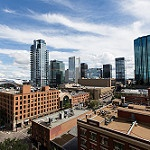

In [244]:
Image.open(train_data.samples[1][0])

In [245]:
train_dataloader = DataLoader(train_data, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=32, shuffle=False)

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x1a890d99810>,
 <torch.utils.data.dataloader.DataLoader at 0x1a88f15ba80>)

In [10]:
# Disply image and label
train_features, train_labels = next(iter(train_dataloader))
train_features.shape, train_labels.shape

(torch.Size([32, 1, 64, 64]), torch.Size([32]))

In [11]:
len(train_features)

32

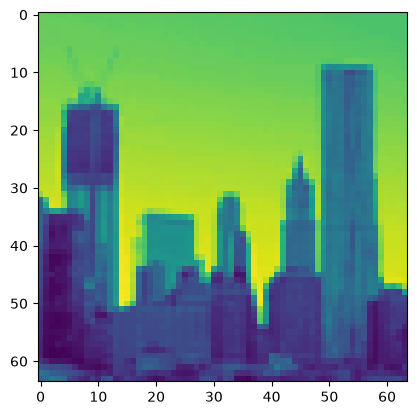

In [12]:
train_shape = train_features[31]
train_shape.permute(1,2,0)
plt.imshow(train_shape.permute(1,2,0))

In [13]:

# torch.randint(low=0, high=32, size=(1,)).item()

[]

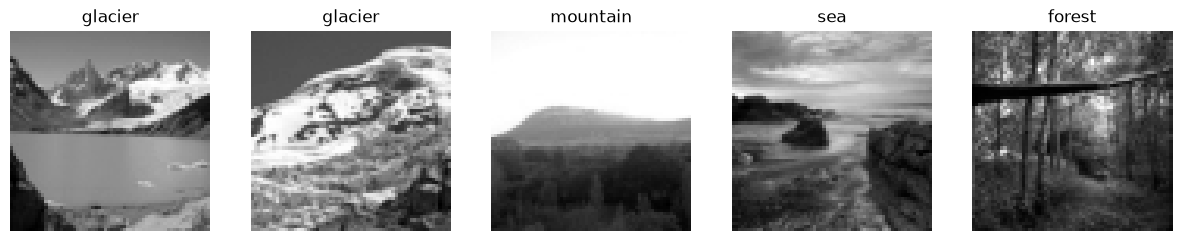

In [14]:
fig = plt.figure(figsize = (15,4))

for x in range(5):
    randn = torch.randint(low=0, high=32, size=(1,)).item()
    plt.subplot(1,5,x+1)
    plt.title(classes[train_labels[x].item()])
    plt.imshow(train_features[x].permute(1,2,0), cmap = "grey")
    plt.axis(False)

plt.plot()

In [181]:
class EnvironPredictModel(nn.Module):
    def __init__(self, input_feature: int, hidden_units: int, output_feature: int):
        super().__init__()

        self.layer_stack_1 = nn.Sequential(
            nn.Conv2d(in_channels = input_feature,
                     out_channels = hidden_units,
                     kernel_size = 3,
                     stride = 1,
                     padding = 0),
            nn.ReLU(),

            nn.Conv2d(in_channels = hidden_units,
                     out_channels = hidden_units,
                     kernel_size = 3,
                     stride = 1,
                     padding = 0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size = 2,
                        stride = 2),
        )

        self.layer_stack_2 = nn.Sequential(
            nn.Conv2d(in_channels = hidden_units,
                     out_channels = hidden_units,
                     kernel_size = 3,
                     stride = 1,
                     padding = 0),
            nn.ReLU(),
            nn.Conv2d(in_channels = hidden_units,
                     out_channels = hidden_units,
                     kernel_size = 3,
                     stride = 1,
                     padding = 0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size = 2,
                        stride = 2),
        )

        self.linear_preperty = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features = hidden_units * 13 * 13,
                     out_features = output_feature)
        )

    def forward(self, x):
        x = self.layer_stack_1(x)
        x = self.layer_stack_2(x)
        # print(x.shape)
        x = self.linear_preperty(x)
        
        return x

In [182]:
torch.manual_seed(42)

model_0 = EnvironPredictModel(input_feature = 1, hidden_units = 10, output_feature = len(classes))
model_0.parameters

<bound method Module.parameters of EnvironPredictModel(
  (layer_stack_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer_stack_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (linear_preperty): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1690, out_features=6, bias=True)
  )
)>

In [183]:
summary(model_0, (1, 64, 64))

Layer (type:depth-idx)                   Output Shape              Param #
├─Sequential: 1-1                        [-1, 10, 30, 30]          --
|    └─Conv2d: 2-1                       [-1, 10, 62, 62]          100
|    └─ReLU: 2-2                         [-1, 10, 62, 62]          --
|    └─Conv2d: 2-3                       [-1, 10, 60, 60]          910
|    └─ReLU: 2-4                         [-1, 10, 60, 60]          --
|    └─MaxPool2d: 2-5                    [-1, 10, 30, 30]          --
├─Sequential: 1-2                        [-1, 10, 13, 13]          --
|    └─Conv2d: 2-6                       [-1, 10, 28, 28]          910
|    └─ReLU: 2-7                         [-1, 10, 28, 28]          --
|    └─Conv2d: 2-8                       [-1, 10, 26, 26]          910
|    └─ReLU: 2-9                         [-1, 10, 26, 26]          --
|    └─MaxPool2d: 2-10                   [-1, 10, 13, 13]          --
├─Sequential: 1-3                        [-1, 6]                   --
|    └─Flat

Layer (type:depth-idx)                   Output Shape              Param #
├─Sequential: 1-1                        [-1, 10, 30, 30]          --
|    └─Conv2d: 2-1                       [-1, 10, 62, 62]          100
|    └─ReLU: 2-2                         [-1, 10, 62, 62]          --
|    └─Conv2d: 2-3                       [-1, 10, 60, 60]          910
|    └─ReLU: 2-4                         [-1, 10, 60, 60]          --
|    └─MaxPool2d: 2-5                    [-1, 10, 30, 30]          --
├─Sequential: 1-2                        [-1, 10, 13, 13]          --
|    └─Conv2d: 2-6                       [-1, 10, 28, 28]          910
|    └─ReLU: 2-7                         [-1, 10, 28, 28]          --
|    └─Conv2d: 2-8                       [-1, 10, 26, 26]          910
|    └─ReLU: 2-9                         [-1, 10, 26, 26]          --
|    └─MaxPool2d: 2-10                   [-1, 10, 13, 13]          --
├─Sequential: 1-3                        [-1, 6]                   --
|    └─Flat

In [188]:
# Declaring train loss and optimizers 
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_0.parameters(), lr = 0.001)
accuracy_fn = torchmetrics.Accuracy(task="multiclass", num_classes=len(classes))

In [189]:
test_feature, test_label = next(iter(test_dataloader))

In [190]:
train_features.shape, test_feature.shape

(torch.Size([32, 1, 64, 64]), torch.Size([32, 1, 64, 64]))

In [191]:
# training model
torch.manual_seed(42)

epochs = 20

for epoch in tqdm(range(epochs)):
    train_loss, train_acc = 0, 0
    model_0.train()
    for batch, (X,y) in enumerate(train_dataloader):
        y_train_logits = model_0(X)
        lossfn = loss(y_train_logits, y)
        train_loss += lossfn.item()
        optimizer.zero_grad()
        lossfn.backward()
        optimizer.step()
        train_pred = torch.argmax(y_train_logits, dim = 1)
        acc = (train_pred == y).float().mean()
        train_acc += acc.item()
        
    train_loss /= len(train_dataloader)
    train_acc /= len(train_dataloader)

    model_0.eval()
    with torch.inference_mode():
        test_loss, test_acc = 0, 0
        for batch, (X_test,y_test) in enumerate(test_dataloader):
            y_test_logits = model_0(X_test)
            test_lossfn = loss(y_test_logits, y_test)
            test_loss += test_lossfn.item()
            
            test_pred = torch.argmax(y_test_logits, dim = 1)
            test_acc_fn = (test_pred == y_test).float().mean()
            test_acc += test_acc_fn.item()
    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)

    print(f"Train Loss: {train_loss} | Train Accuracy: {train_acc}")
    print(f"Test Loss: {test_loss} | Train Accuracy: {test_acc}")

  5%|▌         | 1/20 [01:30<28:43, 90.73s/it]

Train Loss: 0.8069182420510095 | Train Accuracy: 0.7028125790637284
Test Loss: 0.8868786299482305 | Train Accuracy: 0.6697695033347353


 10%|█         | 2/20 [03:13<29:17, 97.64s/it]

Train Loss: 0.7974814539754038 | Train Accuracy: 0.7064429890865074
Test Loss: 0.8771016902111947 | Train Accuracy: 0.6714317373772885


 15%|█▌        | 3/20 [04:50<27:35, 97.40s/it]

Train Loss: 0.7910927404439531 | Train Accuracy: 0.7076847633359644
Test Loss: 0.8800576107299074 | Train Accuracy: 0.6739804966652647


... (30 outputs left out)

 95%|█████████▌| 19/20 [23:55<00:52, 52.69s/it]

Train Loss: 0.7503798443119727 | Train Accuracy: 0.728407365178736
Test Loss: 0.8644941014812347 | Train Accuracy: 0.6745345744680851


100%|██████████| 20/20 [24:45<00:00, 74.30s/it]

Train Loss: 0.7433013797892525 | Train Accuracy: 0.7295463173427451
Test Loss: 0.8568017974178842 | Train Accuracy: 0.6785239361702128


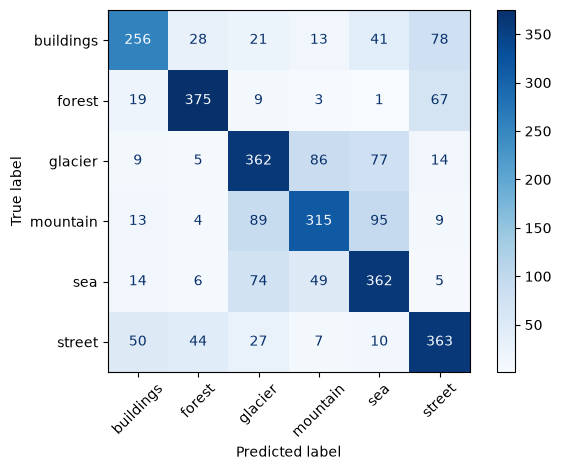

In [192]:
# confusion matrix 

model_0.eval()

all_preds = []
all_labels = []

with torch.inference_mode():
    for X, y in test_dataloader:
        logits = model_0(X)
        preds = torch.argmax(logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.tight_layout()
plt.show()

27


(np.float64(-0.5), np.float64(63.5), np.float64(63.5), np.float64(-0.5))

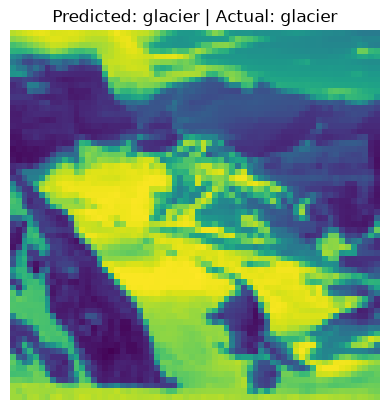

In [198]:
# test_feature, test_label = next(iter(test_dataloader))
random = torch.randint(low = 0, high = 32, size = (1,)).item()
print(random)
predict = model_0(test_feature[random].unsqueeze(dim=0)).argmax(dim=1)
plt.title(f"Predicted: {classes[predict]} | Actual: {classes[test_label[random]]}")
plt.imshow(test_feature[random].permute(1,2,0))
plt.axis(False)

In [199]:
# Classification Report 

model_0.eval()

y_true = []
y_pred = []

with torch.inference_mode():
    for X_test, y_test in test_dataloader:
        logits = model_0(X_test)

        predictions = torch.argmax(logits, dim=1)

        y_true.extend(y_test.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())


report = classification_report(
    y_true,
    y_pred,
    target_names=classes
)

print(report)

              precision    recall  f1-score   support

   buildings       0.71      0.59      0.65       437
      forest       0.81      0.79      0.80       474
     glacier       0.61      0.64      0.63       553
    mountain       0.66      0.59      0.62       525
         sea       0.62      0.71      0.66       510
      street       0.68      0.73      0.70       501

    accuracy                           0.67      3000
   macro avg       0.68      0.67      0.68      3000
weighted avg       0.68      0.67      0.67      3000



(np.float64(-0.5), np.float64(149.5), np.float64(149.5), np.float64(-0.5))

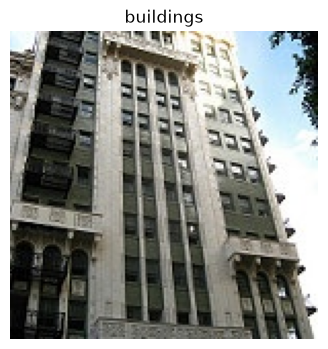

In [233]:
# Let Predict External Image Model
ext_path = BASE_DIR + "/seg_pred/3463.jpg"

transform_ext = transforms.Compose([
    transforms.Resize(size = (64, 64)),
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomHorizontalFlip(p=0.5),
])

image_to_tensor = decode_image(ext_path)
transform_ext = transform_ext(image_to_tensor).type(torch.Tensor)
pred_external = model_0(transform_ext.unsqueeze(dim = 0)).argmax(dim=1)

plt.figure(figsize = (4,4))
plt.title(classes[pred_external])
plt.imshow(image_to_tensor.permute(1,2,0))
plt.axis(False)
# def predictExternalImage(path: str):
#     image_to_tensor = decode_image(path)
    

In [237]:
PATH = Path("saved_models")
PATH.mkdir(parents=True, exist_ok=True)

MODEL_PATH = PATH / "environ_model.pth"

# Save model checkpoint
torch.save({
    "model_state_dict": model_0.state_dict(),
    "model_config": {
        "input_feature": 1,
        "hidden_units": 10,
        "output_feature": len(classes)
    },
    "class_names": classes
}, MODEL_PATH)

print(f"Model saved successfully: {MODEL_PATH}")

Model saved successfully: saved_models\environ_model.pth


In [238]:
# Load model
# checkpoint = torch.load(
#     "saved_models/environ_model.pth",
#     map_location="cpu",
#     weights_only=True
# )
# model = EnvironPredictModel(
#     **checkpoint["model_config"]
# )
# model.load_state_dict(checkpoint["model_state_dict"])
# classes = checkpoint["class_names"]
# model.eval()